In [1]:
# Import library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Baca dataset
data = pd.read_csv("../../data/insurance.csv")

# Tampilkan data awal
display(data.head())

# Ukuran dataset
print("Ukuran dataset:", data.shape)

# Informasi dataset
data.info()

# Statistik deskriptif
display(data.describe())


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


Ukuran dataset: (1338, 7)
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


Jumlah nilai kosong setiap kolom:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Statistik charges:
count     1338.000000
mean     13270.422265
std      12110.011237
min       1121.873900
25%       4740.287150
50%       9382.033000
75%      16639.912515
max      63770.428010
Name: charges, dtype: float64


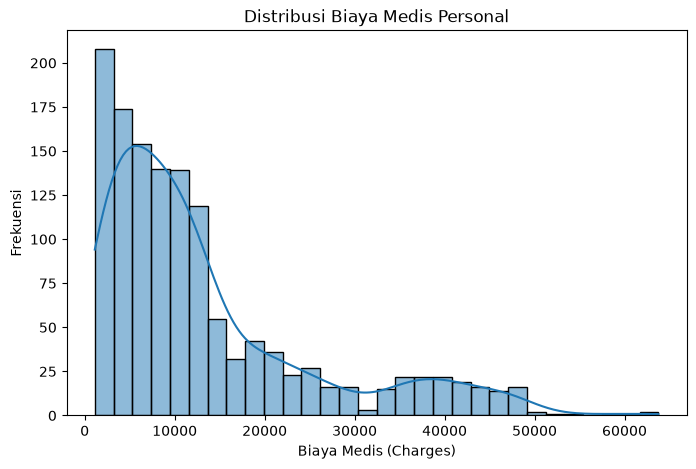

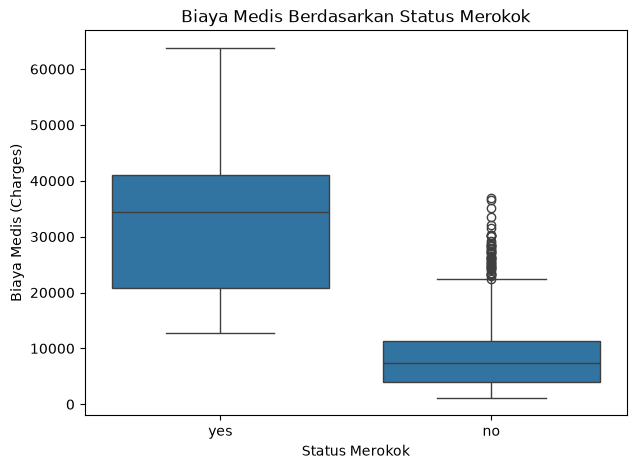

In [2]:
# Periksa nilai kosong
print("Jumlah nilai kosong setiap kolom:")
print(data.isnull().sum())

# Statistik biaya medis
print("\nStatistik charges:")
print(data["charges"].describe())

# Distribusi biaya medis
plt.figure(figsize=(8, 5))
sns.histplot(data=data, x="charges", kde=True)
plt.title("Distribusi Biaya Medis Personal")
plt.xlabel("Biaya Medis (Charges)")
plt.ylabel("Frekuensi")
plt.show()

# Hubungan status merokok dengan biaya medis
plt.figure(figsize=(7, 5))
sns.boxplot(data=data, x="smoker", y="charges")
plt.title("Biaya Medis Berdasarkan Status Merokok")
plt.xlabel("Status Merokok")
plt.ylabel("Biaya Medis (Charges)")
plt.show()


In [ ]:
# Fitur atau variabel bebas
X = data.drop(columns=["charges"])

# Target atau variabel terikat
y = data["charges"]

print("Fitur:", X.columns.tolist())
print("Target:", y.name)


Fitur: ['age', 'sex', 'bmi', 'children', 'smoker', 'region']
Target: charges


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Jumlah data latih:", X_train.shape[0])
print("Jumlah data uji:", X_test.shape[0])


Jumlah data latih: 1070
Jumlah data uji: 268


In [5]:
# Tentukan jenis fitur
numeric_features = [
    "age", "bmi", "children"
]

categorical_features = [
    "sex", "smoker", "region"
]

# Preprocessing fitur kategorikal
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numeric",
            "passthrough",
            numeric_features
        )
    ]
)

# Pipeline preprocessing dan model
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Latih model
model.fit(X_train, y_train)

print("Model Multiple Linear Regression berhasil dilatih.")


Model Multiple Linear Regression berhasil dilatih.


In [6]:
# Prediksi data uji
y_pred = model.predict(X_test)

# Hitung metrik evaluasi
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)

# Tampilkan hasil evaluasi
print("=== Evaluasi Multiple Linear Regression ===")
print(f"R-squared (R2): {r2:.4f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")


=== Evaluasi Multiple Linear Regression ===
R-squared (R2): 0.7836
Mean Squared Error (MSE): 33596915.85
Mean Absolute Error (MAE): 4181.19
Root Mean Squared Error (RMSE): 5796.28


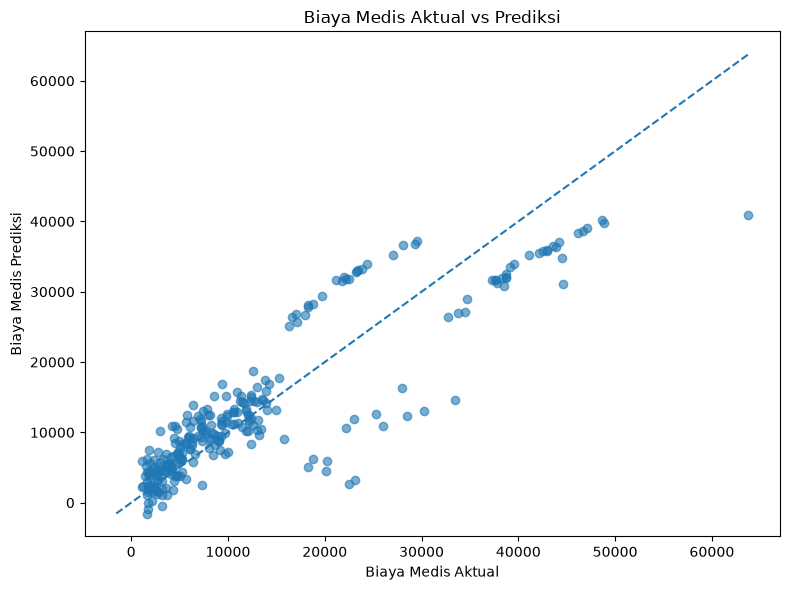

In [7]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.6
)

# Garis prediksi ideal
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Biaya Medis Aktual vs Prediksi")
plt.xlabel("Biaya Medis Aktual")
plt.ylabel("Biaya Medis Prediksi")
plt.tight_layout()
plt.show()


In [8]:
# Nama fitur setelah encoding
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Koefisien regresi
coefficients = model.named_steps[
    "regressor"
].coef_

coef_df = pd.DataFrame({
    "Fitur": feature_names,
    "Koefisien": coefficients
})

coef_df["Nilai Absolut"] = coef_df["Koefisien"].abs()

display(
    coef_df.sort_values(
        "Nilai Absolut",
        ascending=False
    )
)


,Fitur,Koefisien,Nilai Absolut
3,categorical__smoker_yes,11825.564428,11825.564428
2,categorical__smoker_no,-11825.564428,11825.564428
4,categorical__region_northeast,459.585244,459.585244
10,numeric__children,425.278784,425.278784
7,categorical__region_southwest,-350.214110,350.214110
9,numeric__bmi,337.092552,337.092552
8,numeric__age,256.975706,256.975706
6,categorical__region_southeast,-198.279052,198.279052
5,categorical__region_northwest,88.907918,88.907918
0,categorical__sex_female,9.295846,9.295846


### Analisis Hasil Multiple Linear Regression

Pada praktikum ini, digunakan dataset *Medical Cost Personal Datasets* untuk memprediksi biaya medis personal berdasarkan usia, jenis kelamin, BMI, jumlah anak, status merokok, dan wilayah tempat tinggal. Variabel `charges` ditetapkan sebagai target prediksi, sedangkan variabel lainnya digunakan sebagai fitur.

Dataset dibagi menjadi 80% data latih dan 20% data uji. Fitur kategorikal diproses menggunakan One-Hot Encoding, kemudian model Multiple Linear Regression dilatih menggunakan data latih dan dievaluasi pada data uji.

Kinerja model dievaluasi menggunakan R-squared, Mean Squared Error (MSE), dan Mean Absolute Error (MAE). Nilai R-squared digunakan untuk mengukur kemampuan model menjelaskan variasi biaya medis, sedangkan MSE dan MAE mengukur besarnya kesalahan prediksi. Nilai metrik aktual diperoleh dari hasil eksekusi program.

Grafik biaya medis aktual dan prediksi digunakan untuk mengamati kedekatan hasil prediksi dengan nilai sebenarnya. Apabila titik-titik berada dekat garis diagonal, prediksi model cenderung mendekati nilai aktual. Penyebaran titik yang jauh dari garis menunjukkan adanya kesalahan prediksi.

Model Multiple Linear Regression memberikan pendekatan hubungan linear antara fitur dan biaya medis. Namun, ketepatan prediksi bergantung pada karakteristik data dan seberapa baik hubungan tersebut dapat direpresentasikan oleh model linear.

**Kesimpulan:** Model telah dibangun untuk memprediksi biaya medis personal menggunakan Multiple Linear Regression. Kualitas model perlu disimpulkan berdasarkan nilai R-squared, MSE, MAE, dan grafik hasil prediksi yang diperoleh dari pengujian.